In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = [5,7,8,8,12,None,"8 "]
df =pd.Series(df)

In [59]:
# Q1
df = df.astype(str).str.strip()
df = pd.to_numeric(df,errors="coerce")

df


,0
0,5.0
1,7.0
2,8.0
3,8.0
4,12.0
5,NaN
6,8.0


In [70]:
# Q2
median =df.median()

df.fillna(median,inplace=True)
df

,0
0,5.0
1,7.0
2,8.0
3,8.0
4,12.0
5,8.0
6,8.0


In [69]:
# Q3
arr=df.to_numpy()

q1 = np.percentile(arr,25)
q3 = np.percentile(arr,75)
IQR = q3-q1
flag_value = (q3+1.5*IQR)
print("IQR : ",IQR)
print("flag_value : ",flag_value)
print("Outlier :")
for x in arr:
    if x>flag_value:
        print(" ",x)


IQR :  0.5
flag_value :  8.75
Outlier :
  12.0


In [73]:
# Q4
data ={
    'Scores':[5,7,8,8,12,8],
    'Hours': [2,3,4,0,4,2]
}
df1 = pd.DataFrame(data)

df1['Efficency_Score']= np.where(df1['Hours']>0,df1['Scores']/df1['Hours'],0)

df1 = df1.sort_values(by='Efficency_Score',ascending=False)
df1

,Scores,Hours,Efficency_Score
5,8,2,4.000000
4,12,4,3.000000
0,5,2,2.500000
1,7,3,2.333333
2,8,4,2.000000
3,8,0,0.000000


In [101]:
# Q5
mean_score=np.mean(df1['Scores'])
median_score = np.median(df1['Scores'])
mode_score = df1['Scores'].mode()[0]

print("Mean : ",mean_score)
print("Median : ",median_score)
print("Mode : ",mode_score)


Mean :  8.0
Median :  8.0
Mode :  8


In [80]:
# Q6
varian_score = np.var(df1['Scores'])
std_score = np.std(df1['Scores'])

print("Variance : ",varian_score)
print("Standard Deviation : ",std_score)

Variance :  4.333333333333333
Standard Deviation :  2.0816659994661326


(array([1., 1., 3., 0., 1.]),
 array([ 5. ,  6.4,  7.8,  9.2, 10.6, 12. ]),
 <BarContainer object of 5 artists>)

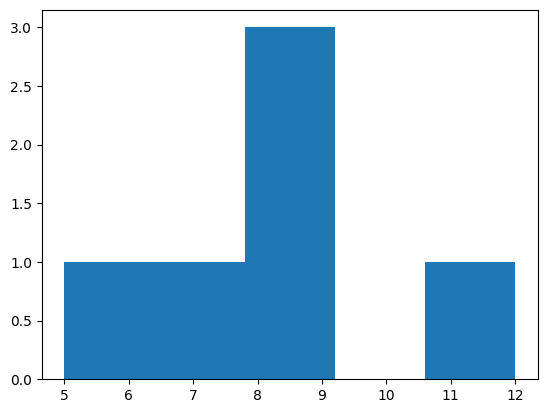

In [82]:
# Q7
plt.hist(df1['Scores'],bins=5)

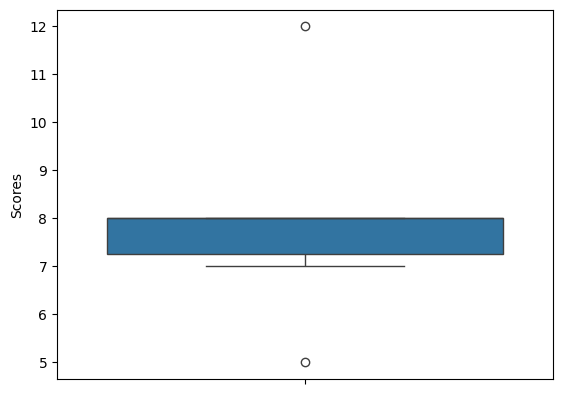

In [89]:
# Q8
sns.boxplot(df1['Scores'])
plt.show()

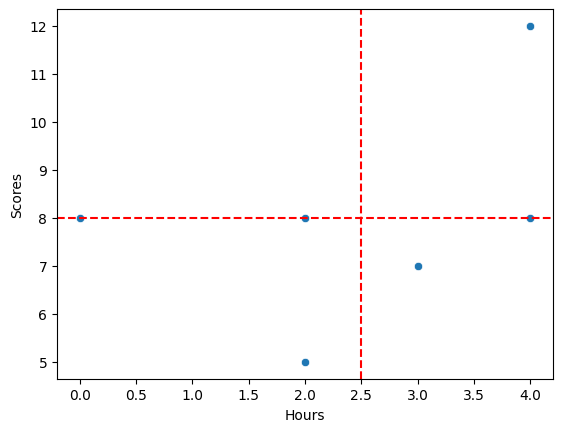

In [91]:
# Q9
sns.scatterplot(x='Hours',y='Scores',data=df1)
plt.axvline(x=np.mean(df1['Hours']),color='red',linestyle='--')
plt.axhline(y=np.mean(df1['Scores']),color='red',linestyle='--')
plt.show()

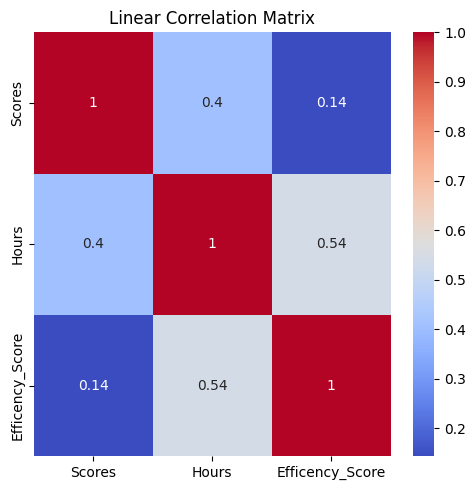

----------------------


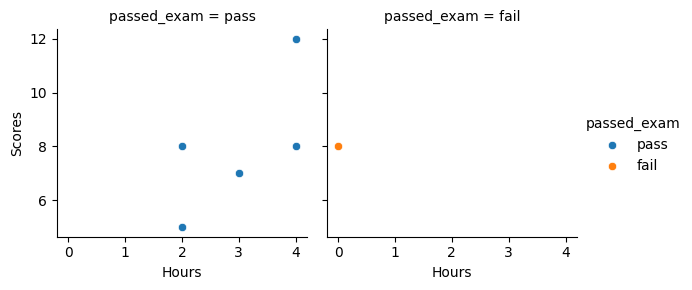

In [100]:
# Q10
df1['passed_exam']=['pass','pass','pass','pass','pass','fail']

numeric_df = df1.select_dtypes(include='number')
corr = numeric_df.corr()

plt.figure(figsize=(5,5))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Linear Correlation Matrix')
plt.tight_layout()
plt.show()

print("----------------------")

g = sns.FacetGrid(df1,col='passed_exam',hue='passed_exam')
g.map(sns.scatterplot,'Hours','Scores')

g.add_legend()
plt.show()
